# Telecom Customer Churn Prediction

## Objective
Build a machine learning model to predict whether a telecom customer is likely to churn.

### Business Goal
Identify customers who are likely to leave the company so that proactive retention offers can be provided.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
import pandas as pd
from pathlib import Path

# Find the CSV file inside the project folder
csv_files = list(Path(".").rglob("*.csv"))

print("CSV files found:")
for file in csv_files:
    print(file)

CSV files found:
archive (1)\WA_Fn-UseC_-Telco-Customer-Churn.csv


In [7]:
csv_path = csv_files[0]

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (7043, 21)


In [8]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 7043
Columns: 21


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [11]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Series([], dtype: int64)


In [12]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [13]:
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


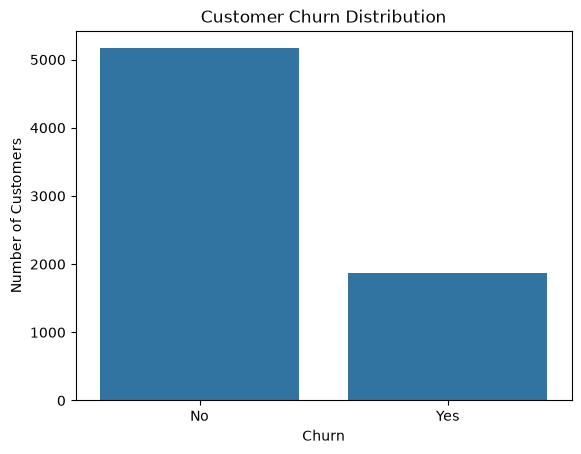

In [21]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [14]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [15]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [16]:
print("Blank TotalCharges:", (df["TotalCharges"] == " ").sum())

Blank TotalCharges: 11


In [17]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [18]:
print("Missing TotalCharges after conversion:", df["TotalCharges"].isnull().sum())

Missing TotalCharges after conversion: 11


In [19]:
df = df.dropna(subset=["TotalCharges"])

In [20]:
print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (7032, 21)


In [22]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [23]:
df = df.drop("customerID", axis=1)

In [24]:
print("Columns after removing customerID:")
print(df.columns.tolist())

Columns after removing customerID:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [25]:
print(df["Churn"].value_counts())

Churn
No     5163
Yes    1869
Name: count, dtype: int64


In [26]:
print("\nChurn percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)


Churn percentage:
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


In [27]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print(df["Churn"].value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


In [28]:


print("Final dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum().sum())
print("\nData types:")
print(df.dtypes)

Final dataset shape: (7032, 20)

Missing values:
0

Data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


In [29]:
# Numerical features
numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Categorical features
categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [30]:
contract_churn = (
    df.groupby("Contract")["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(contract_churn)

Contract
Month-to-month    42.709677
One year          11.277174
Two year           2.848665
Name: Churn, dtype: float64


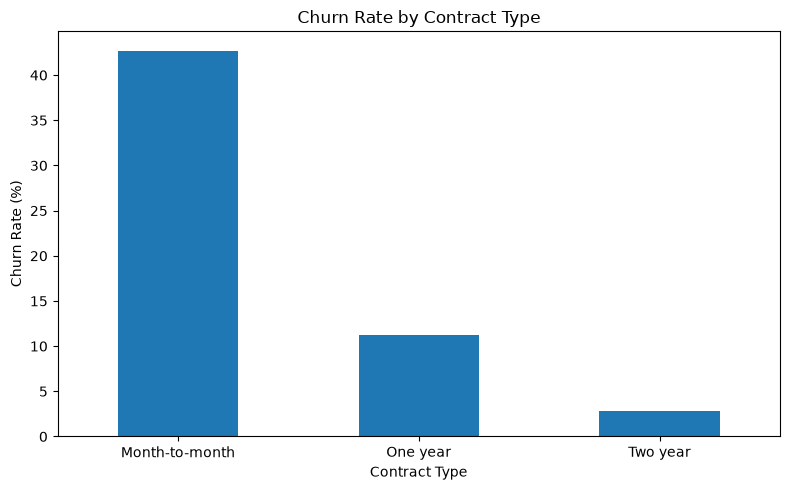

In [31]:
plt.figure(figsize=(8, 5))

contract_churn.plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [32]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(internet_churn)

InternetService
Fiber optic    41.892765
DSL            18.998344
No              7.434211
Name: Churn, dtype: float64


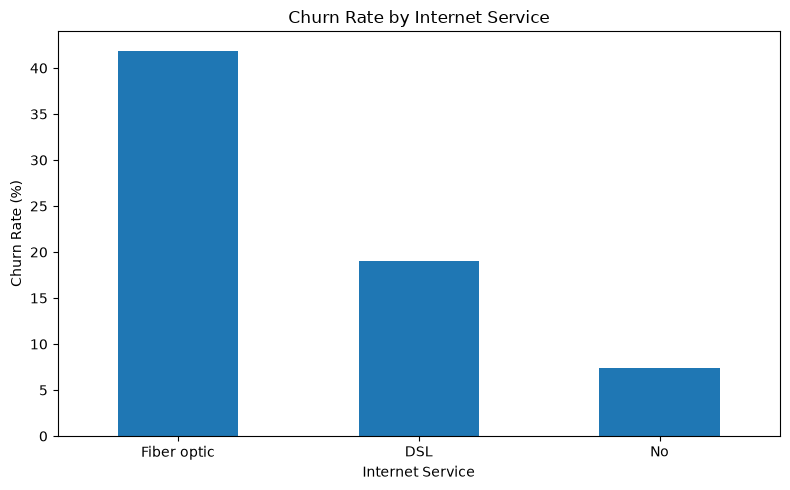

In [33]:
plt.figure(figsize=(8, 5))

internet_churn.plot(kind="bar")

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [34]:
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(payment_churn)

PaymentMethod
Electronic check             45.285412
Mailed check                 19.201995
Bank transfer (automatic)    16.731518
Credit card (automatic)      15.253123
Name: Churn, dtype: float64


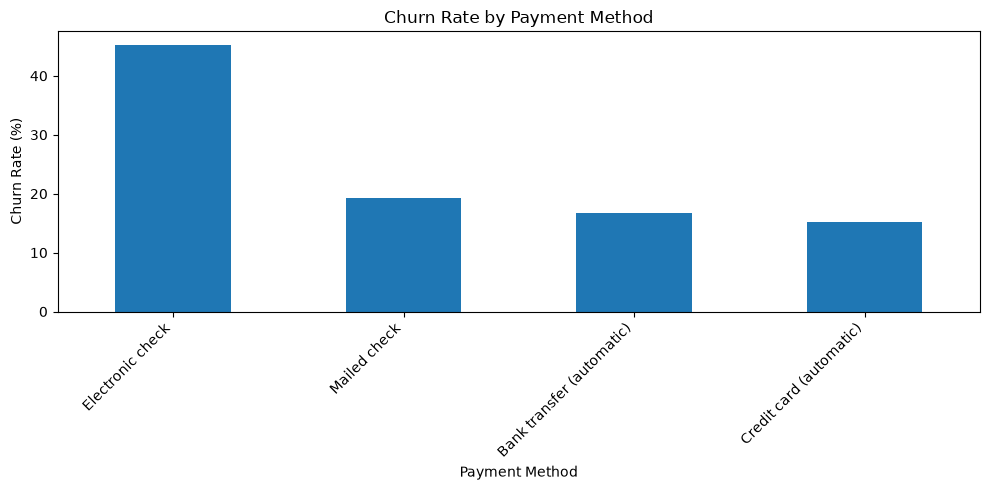

In [35]:
plt.figure(figsize=(10, 5))

payment_churn.plot(kind="bar")

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [36]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 60, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-60 months",
        "61-72 months"
    ],
    include_lowest=True
)

In [37]:
tenure_churn = (
    df.groupby("TenureGroup", observed=True)["Churn"]
    .mean()
    .mul(100)
)

print(tenure_churn)

TenureGroup
0-12 months     47.678161
13-24 months    28.710938
25-48 months    20.388959
49-60 months    14.423077
61-72 months     6.609808
Name: Churn, dtype: float64


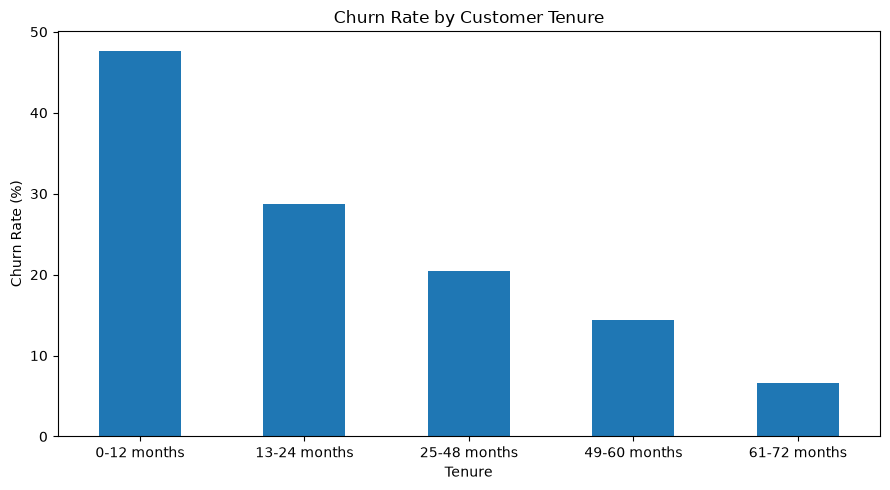

In [38]:
plt.figure(figsize=(9, 5))

tenure_churn.plot(kind="bar")

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

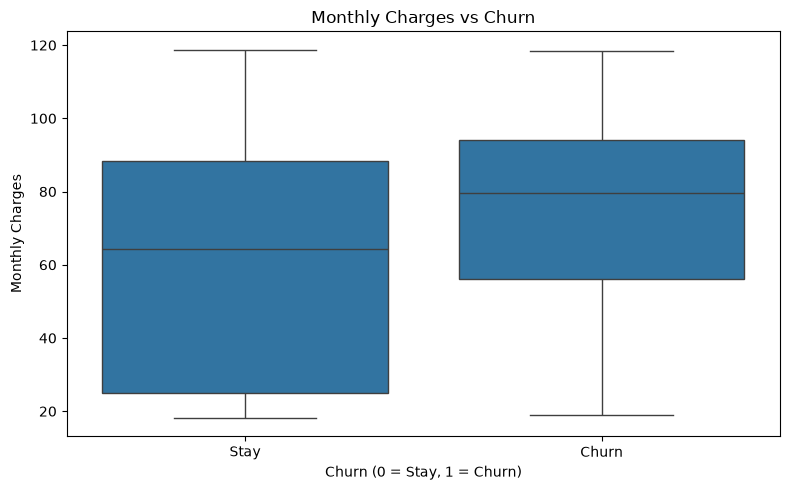

In [39]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn (0 = Stay, 1 = Churn)")
plt.ylabel("Monthly Charges")
plt.xticks([0, 1], ["Stay", "Churn"])
plt.tight_layout()
plt.show()

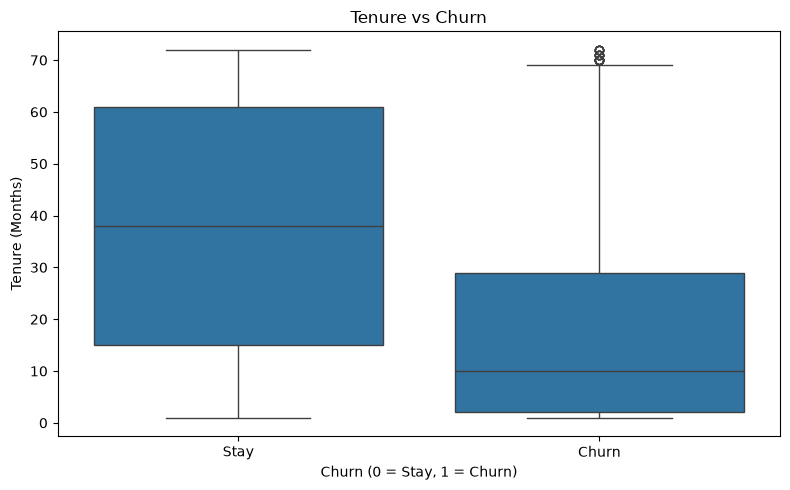

In [40]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure vs Churn")
plt.xlabel("Churn (0 = Stay, 1 = Churn)")
plt.ylabel("Tenure (Months)")
plt.xticks([0, 1], ["Stay", "Churn"])
plt.tight_layout()
plt.show()

In [41]:
feature_churn_rates = {}

for feature in categorical_features:
    churn_rate = (
        df.groupby(feature)["Churn"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )
    
    feature_churn_rates[feature] = churn_rate

for feature, rates in feature_churn_rates.items():
    print("\n" + "=" * 50)
    print(feature)
    print(rates)


gender
gender
Female    26.959518
Male      26.204565
Name: Churn, dtype: float64

Partner
Partner
No     32.976092
Yes    19.717065
Name: Churn, dtype: float64

Dependents
Dependents
No     31.279140
Yes    15.531205
Name: Churn, dtype: float64

PhoneService
PhoneService
Yes    26.747481
No     25.000000
Name: Churn, dtype: float64

MultipleLines
MultipleLines
Yes                 28.648466
No                  25.081241
No phone service    25.000000
Name: Churn, dtype: float64

InternetService
InternetService
Fiber optic    41.892765
DSL            18.998344
No              7.434211
Name: Churn, dtype: float64

OnlineSecurity
OnlineSecurity
No                     41.778667
Yes                    14.640199
No internet service     7.434211
Name: Churn, dtype: float64

OnlineBackup
OnlineBackup
No                     39.941691
Yes                    21.567010
No internet service     7.434211
Name: Churn, dtype: float64

DeviceProtection
DeviceProtection
No                     39.140271
Y

In [42]:
numerical_summary = df.groupby("Churn")[numerical_features].mean().T

numerical_summary.columns = ["Stay", "Churn"]

print(numerical_summary)

                       Stay        Churn
SeniorCitizen      0.128995     0.254682
tenure            37.650010    17.979133
MonthlyCharges    61.307408    74.441332
TotalCharges    2555.344141  1531.796094


## Preliminary Feature Analysis

The exploratory analysis will be used to identify customer characteristics associated with churn.

Key areas investigated:

- Contract type
- Internet service
- Payment method
- Customer tenure
- Monthly charges
- Total charges
- Customer support and security services
- Demographic and household characteristics

Features showing substantial differences in churn rates will be considered important predictors for the machine learning model.

Note: These are exploratory relationships and do not by themselves prove causation.

In [43]:
df = df.drop("TenureGroup", axis=1)
print(df.shape)
print(df.columns.tolist())

(7032, 20)
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [44]:
# Separate features and target

X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7032, 19)
Target shape: (7032,)


In [45]:
# Identify categorical and numerical columns

categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


C:\Users\moham\AppData\Local\Temp\ipykernel_28428\2328153748.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()


In [49]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)



Features shape: (7032, 19)
Target shape: (7032,)


In [50]:
categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


C:\Users\moham\AppData\Local\Temp\ipykernel_28428\2081442550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()


In [51]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (5625, 19)
Testing features: (1407, 19)


In [53]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [54]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5625, 45)
Processed testing shape: (1407, 45)


In [55]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Logistic Regression model created!")

Logistic Regression model created!


In [56]:
model.fit(X_train_processed, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [57]:
y_pred = model.predict(X_test_processed)

print("Predictions generated!")
print(y_pred[:20])

Predictions generated!
[0 1 0 0 0 0 0 0 1 0 1 0 1 0 0 1 1 1 0 0]


In [58]:
y_probability = model.predict_proba(X_test_processed)[:, 1]

print("First 10 churn probabilities:")
print(y_probability[:10])

First 10 churn probabilities:
[0.01751303 0.59192131 0.00482103 0.20165167 0.1015014  0.4718449
 0.02651812 0.16543101 0.67959955 0.01552463]


In [59]:
customer_prediction = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Churn_Probability": y_probability,
    "Predicted_Churn": y_pred
})

customer_prediction["Prediction"] = customer_prediction["Predicted_Churn"].map({
    0: "Likely to Stay",
    1: "Likely to Churn"
})

customer_prediction.head(10)

,Actual_Churn,Churn_Probability,Predicted_Churn,Prediction
0,0,0.017513,0,Likely to Stay
1,0,0.591921,1,Likely to Churn
2,0,0.004821,0,Likely to Stay
3,1,0.201652,0,Likely to Stay
4,0,0.101501,0,Likely to Stay
5,1,0.471845,0,Likely to Stay
6,0,0.026518,0,Likely to Stay
7,0,0.165431,0,Likely to Stay
8,1,0.679600,1,Likely to Churn
9,0,0.015525,0,Likely to Stay


In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.8038
Precision: 0.6485
Recall   : 0.5722
F1 Score : 0.6080


In [62]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stay", "Churn"]
))
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

              precision    recall  f1-score   support

        Stay       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

Confusion Matrix:
[[917 116]
 [160 214]]


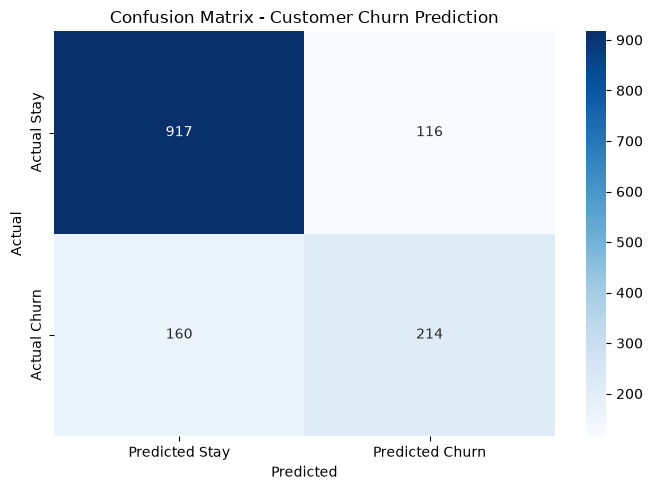

In [63]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Stay", "Predicted Churn"],
    yticklabels=["Actual Stay", "Actual Churn"]
)

plt.title("Confusion Matrix - Customer Churn Prediction")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [65]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives  :", tp)
print("Churn customers correctly identified:", tp)
print("Non-churn customers misclassified:", fp)

True Negatives : 917
False Positives: 116
False Negatives: 160
True Positives  : 214
Churn customers correctly identified: 214
Non-churn customers misclassified: 116


## Business Interpretation

The model helps the telecom company identify customers who are likely to churn.

### False Positive
A loyal customer is incorrectly classified as likely to churn.

This may cause the company to provide an unnecessary retention offer. 
Although this creates some additional cost, the customer is still retained.

### False Negative
A customer who is actually going to churn is classified as likely to stay.

This is potentially more costly because the company may lose the customer and the future revenue associated with that customer.

### Business Decision

For a telecom retention campaign, missing a genuine churn customer can be more costly than incorrectly targeting a loyal customer.

Therefore, improving **recall for the Churn class** can be more important than maximizing accuracy alone.

However, the company should also control false positives because unnecessary discounts and retention offers increase campaign costs.

## Proposed Improvement

One improvement would be to optimize the classification threshold instead of automatically using 0.50.

For example, the company could use a lower threshold such as 0.40 to identify more customers who are at risk of churn.

This could increase recall and help reduce false negatives, allowing the company to intervene with more potentially lost customers.

The final threshold should be selected based on the financial cost of:
1. Losing a customer who churns.
2. Providing a retention offer to a customer who would have stayed.

In [66]:
# Get feature names after preprocessing

feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))
print("\nFirst 20 features:")
print(feature_names[:20])

Number of processed features: 45

First 20 features:
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'cat__gender_Female' 'cat__gender_Male'
 'cat__Partner_No' 'cat__Partner_Yes' 'cat__Dependents_No'
 'cat__Dependents_Yes' 'cat__PhoneService_No' 'cat__PhoneService_Yes'
 'cat__MultipleLines_No' 'cat__MultipleLines_No phone service'
 'cat__MultipleLines_Yes' 'cat__InternetService_DSL'
 'cat__InternetService_Fiber optic' 'cat__InternetService_No'
 'cat__OnlineSecurity_No' 'cat__OnlineSecurity_No internet service']


In [67]:
# Extract model coefficients

coefficients = model.coef_[0]

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df.head()

,Feature,Coefficient,Absolute_Coefficient
0,num__SeniorCitizen,0.071011,0.071011
1,num__tenure,-1.352313,1.352313
2,num__MonthlyCharges,-0.541006,0.541006
3,num__TotalCharges,0.644014,0.644014
4,cat__gender_Female,-0.142779,0.142779


In [68]:
# Strongest features based on absolute coefficient

strongest_features = coefficient_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

strongest_features.head(15)

,Feature,Coefficient,Absolute_Coefficient
1,num__tenure,-1.352313,1.352313
38,cat__Contract_Two year,-0.779030,0.779030
3,num__TotalCharges,0.644014,0.644014
15,cat__InternetService_DSL,-0.616132,0.616132
36,cat__Contract_Month-to-month,0.613846,0.613846
16,cat__InternetService_Fiber optic,0.590184,0.590184
2,num__MonthlyCharges,-0.541006,0.541006
39,cat__PaperlessBilling_No,-0.300387,0.300387
12,cat__MultipleLines_No,-0.293470,0.293470
17,cat__InternetService_No,-0.283724,0.283724


In [69]:
positive_factors = coefficient_df[
    coefficient_df["Coefficient"] > 0
].sort_values(
    by="Coefficient",
    ascending=False
)

print("Top factors associated with higher churn:")
print(positive_factors.head(10))

Top factors associated with higher churn:
                                Feature  Coefficient  Absolute_Coefficient
3                     num__TotalCharges     0.644014              0.644014
36         cat__Contract_Month-to-month     0.613846              0.613846
16     cat__InternetService_Fiber optic     0.590184              0.590184
32                 cat__StreamingTV_Yes     0.191113              0.191113
43  cat__PaymentMethod_Electronic check     0.180671              0.180671
35             cat__StreamingMovies_Yes     0.177076              0.177076
18               cat__OnlineSecurity_No     0.164459              0.164459
27                  cat__TechSupport_No     0.142949              0.142949
14               cat__MultipleLines_Yes     0.088164              0.088164
0                    num__SeniorCitizen     0.071011              0.071011


In [70]:
negative_factors = coefficient_df[
    coefficient_df["Coefficient"] < 0
].sort_values(
    by="Coefficient",
    ascending=True
)

print("Top factors associated with lower churn:")
print(negative_factors.head(10))

Top factors associated with lower churn:
                                      Feature  Coefficient  \
1                                 num__tenure    -1.352313   
38                     cat__Contract_Two year    -0.779030   
15                   cat__InternetService_DSL    -0.616132   
2                         num__MonthlyCharges    -0.541006   
39                   cat__PaperlessBilling_No    -0.300387   
12                      cat__MultipleLines_No    -0.293470   
19    cat__OnlineSecurity_No internet service    -0.283724   
17                    cat__InternetService_No    -0.283724   
25  cat__DeviceProtection_No internet service    -0.283724   
28       cat__TechSupport_No internet service    -0.283724   

    Absolute_Coefficient  
1               1.352313  
38              0.779030  
15              0.616132  
2               0.541006  
39              0.300387  
12              0.293470  
19              0.283724  
17              0.283724  
25              0.283724  
28    

In [71]:
top_10_factors = coefficient_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
).head(10).copy()

top_10_factors["Effect"] = np.where(
    top_10_factors["Coefficient"] > 0,
    "Higher Churn",
    "Lower Churn"
)

top_10_factors[
    ["Feature", "Coefficient", "Effect"]
]

,Feature,Coefficient,Effect
1,num__tenure,-1.352313,Lower Churn
38,cat__Contract_Two year,-0.779030,Lower Churn
3,num__TotalCharges,0.644014,Higher Churn
15,cat__InternetService_DSL,-0.616132,Lower Churn
36,cat__Contract_Month-to-month,0.613846,Higher Churn
16,cat__InternetService_Fiber optic,0.590184,Higher Churn
2,num__MonthlyCharges,-0.541006,Lower Churn
39,cat__PaperlessBilling_No,-0.300387,Lower Churn
12,cat__MultipleLines_No,-0.293470,Lower Churn
17,cat__InternetService_No,-0.283724,Lower Churn


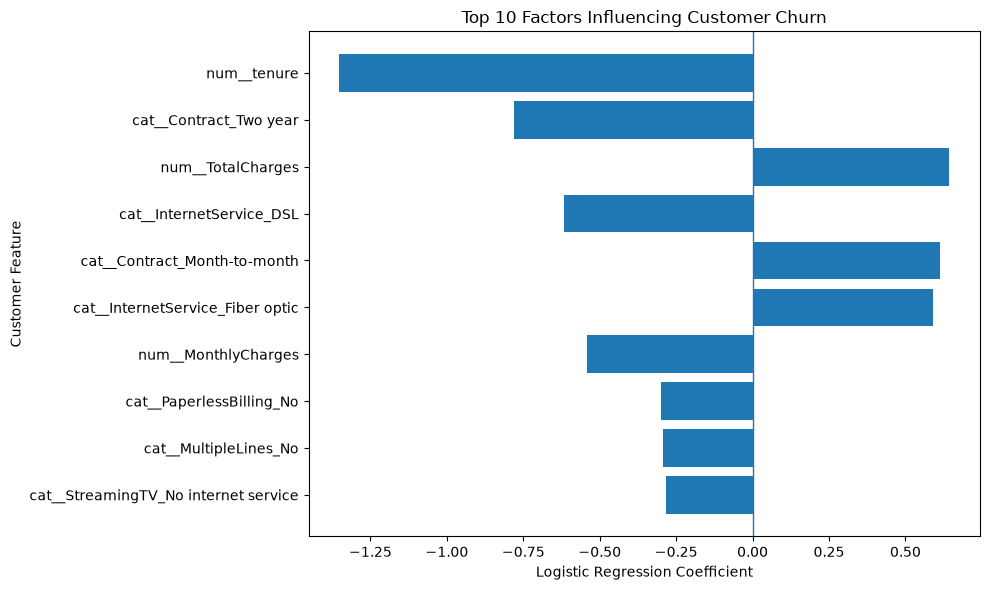

In [72]:
top_10_plot = coefficient_df.sort_values(
    by="Absolute_Coefficient",
    ascending=True
).tail(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_plot["Feature"],
    top_10_plot["Coefficient"]
)

plt.axvline(
    x=0,
    linewidth=1
)

plt.title("Top 10 Factors Influencing Customer Churn")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Customer Feature")
plt.tight_layout()
plt.show()

In [73]:
top_10_factors["Readable Feature"] = (
    top_10_factors["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
    .str.replace("_", " ", regex=False)
)

top_10_factors[
    ["Readable Feature", "Coefficient", "Effect"]
]

,Readable Feature,Coefficient,Effect
1,tenure,-1.352313,Lower Churn
38,Contract Two year,-0.779030,Lower Churn
3,TotalCharges,0.644014,Higher Churn
15,InternetService DSL,-0.616132,Lower Churn
36,Contract Month-to-month,0.613846,Higher Churn
16,InternetService Fiber optic,0.590184,Higher Churn
2,MonthlyCharges,-0.541006,Lower Churn
39,PaperlessBilling No,-0.300387,Lower Churn
12,MultipleLines No,-0.293470,Lower Churn
17,InternetService No,-0.283724,Lower Churn


## Strongest Churn Factors

The Logistic Regression model was analyzed using its feature coefficients.

### Interpretation

- Positive coefficients indicate characteristics associated with higher churn probability.
- Negative coefficients indicate characteristics associated with lower churn probability.
- Larger absolute coefficients indicate stronger influence on the model prediction.

### Business Meaning

The strongest churn-related characteristics can be used by the telecom company to identify customers requiring proactive retention.

For example, customers associated with higher-risk contract, service, payment, or tenure characteristics can be prioritized for retention campaigns.

Customers associated with lower churn risk can receive normal customer-service treatment rather than costly retention incentives.

The coefficient analysis provides model interpretability and helps management understand why certain customers are classified as likely to churn.

"The model identifies factors associated with higher or lower predicted churn probability; these relationships should not be interpreted as proof of causation."

In [74]:
# Create customer-level prediction table

results = X_test.copy()

results["Actual_Churn"] = y_test.values
results["Churn_Probability"] = y_probability
results["Predicted_Churn"] = y_pred

results["Churn_Status"] = results["Predicted_Churn"].map({
    0: "Likely to Stay",
    1: "Likely to Churn"
})

results = results.sort_values(
    by="Churn_Probability",
    ascending=False
)

results.head(20)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability,Predicted_Churn,Churn_Status
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,1,0.847466,1,Likely to Churn
3159,Male,1,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,94.85,335.75,0,0.845807,1,Likely to Churn
2631,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,99.25,665.45,1,0.826700,1,Likely to Churn
4585,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,0.822502,1,Likely to Churn
3727,Female,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,96.60,291.90,1,0.816005,1,Likely to Churn
2797,Male,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,100.95,329.95,1,0.815978,1,Likely to Churn
582,Female,1,No,No,4,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,89.20,346.20,1,0.815600,1,Likely to Churn
933,Female,1,No,No,4,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,84.60,360.10,1,0.810614,1,Likely to Churn
6240,Male,0,No,Yes,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,93.30,93.30,1,0.793693,1,Likely to Churn
2516,Female,1,No,No,16,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,96.40,1581.20,1,0.791580,1,Likely to Churn


In [75]:
def classify_risk(probability):
    if probability >= 0.75:
        return "High Risk"
    elif probability >= 0.50:
        return "Medium Risk"
    else:
        return "Low Risk"

results["Risk_Level"] = results["Churn_Probability"].apply(
    classify_risk
)

results[
    [
        "Churn_Probability",
        "Churn_Status",
        "Risk_Level",
        "Actual_Churn"
    ]
].head(20)

,Churn_Probability,Churn_Status,Risk_Level,Actual_Churn
3380,0.847466,Likely to Churn,High Risk,1
3159,0.845807,Likely to Churn,High Risk,0
2631,0.826700,Likely to Churn,High Risk,1
4585,0.822502,Likely to Churn,High Risk,1
3727,0.816005,Likely to Churn,High Risk,1
2797,0.815978,Likely to Churn,High Risk,1
582,0.815600,Likely to Churn,High Risk,1
933,0.810614,Likely to Churn,High Risk,1
6240,0.793693,Likely to Churn,High Risk,1
2516,0.791580,Likely to Churn,High Risk,1


In [76]:
print("=" * 60)
print("FINAL MODEL PERFORMANCE")
print("=" * 60)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\n" + "=" * 60)
print("CONFUSION MATRIX ANALYSIS")
print("=" * 60)

print(f"True Negatives  : {tn}")
print(f"False Positives : {fp}")
print(f"False Negatives : {fn}")
print(f"True Positives  : {tp}")

print("\nBusiness interpretation:")
print(f"- {tp} actual churn customers were correctly identified.")
print(f"- {fp} customers who stayed were incorrectly flagged as churn.")
print(f"- {fn} customers who churned were missed by the model.")

FINAL MODEL PERFORMANCE
Accuracy  : 0.8038
Precision : 0.6485
Recall    : 0.5722
F1 Score  : 0.6080

CONFUSION MATRIX ANALYSIS
True Negatives  : 917
False Positives : 116
False Negatives : 160
True Positives  : 214

Business interpretation:
- 214 actual churn customers were correctly identified.
- 116 customers who stayed were incorrectly flagged as churn.
- 160 customers who churned were missed by the model.


In [77]:
actual_churn_customers = (y_test == 1).sum()

churn_identification_rate = (
    tp / actual_churn_customers
) * 100

print(
    f"Churn customers correctly identified: "
    f"{churn_identification_rate:.2f}%"
)

Churn customers correctly identified: 57.22%


## Business Analysis

### 1. Correctly Identified Churn Customers

The model correctly identified customers who were actually going to churn. These customers can be targeted with proactive retention campaigns such as:

- Personalized discounts
- Contract upgrade offers
- Service improvements
- Customer-support intervention
- Loyalty benefits

Early intervention can help reduce customer loss and protect recurring revenue.

### 2. Incorrectly Flagged Loyal Customers

False positives occur when the model predicts that a customer will churn even though the customer actually stays.

The main business cost is unnecessary retention spending. For example, the company may provide a discount or special offer to a customer who would have remained anyway.

However, this may be an acceptable cost if the retention campaign is relatively inexpensive.

### 3. Missed Churn Customers

False negatives occur when the model predicts that a customer will stay even though the customer actually churns.

This can be more expensive because the company may lose:

- Future subscription revenue
- Customer lifetime value
- Cross-selling opportunities
- Money already invested in acquiring the customer

Therefore, for a churn-retention problem, reducing false negatives is particularly important.

### Business Priority

The telecom company should generally prioritize **recall for the churn class**, while also monitoring the cost of false-positive retention offers.

The ideal decision threshold should therefore be based not only on model accuracy but also on the financial cost of customer churn and retention campaigns.

## Business Recommendation

The telecom company should use the model as an early-warning system for customer churn.

Customers with high predicted churn probability should be prioritized for proactive retention campaigns.

A practical strategy would be:

1. Identify high-risk customers using churn probability.
2. Prioritize customers with high probability and high customer value.
3. Offer targeted retention incentives rather than giving discounts to every customer.
4. Monitor whether contacted customers remain with the company.
5. Retrain the model periodically using new customer behavior data.

The company should not treat the model prediction as a final decision. It should be used as a decision-support tool for the customer retention team.

## Proposed Technical Improvement

One improvement is to optimize the probability threshold instead of automatically using 0.50.

The standard 0.50 threshold treats false positives and false negatives equally. In a telecom churn problem, missing a genuine churn customer can potentially be more expensive than contacting a customer who would have stayed.

The company could therefore evaluate thresholds such as 0.30, 0.40, 0.50, 0.60, and 0.70 and select a threshold based on the business cost of false negatives and false positives.

Another future improvement would be to compare Logistic Regression with models such as Random Forest, Gradient Boosting, or XGBoost and select the model that provides the best balance between predictive performance and business interpretability.

# Final Project Conclusion

This project developed a machine learning solution for predicting telecom customer churn using the Telco Customer Churn dataset.

The dataset was cleaned and analyzed to understand customer characteristics associated with churn. Numerical and categorical customer attributes were prepared using appropriate preprocessing techniques.

A Logistic Regression model was trained to estimate the probability that a customer would leave the company. Customers were then classified into two groups:

- **Likely to Churn**
- **Likely to Stay**

The model was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

The confusion matrix helped identify:

- True Positives: customers who were correctly identified as churners.
- True Negatives: customers who were correctly identified as non-churners.
- False Positives: loyal customers incorrectly flagged as churners.
- False Negatives: actual churners missed by the model.

From a business perspective, false negatives can be particularly costly because they represent customers who may leave without receiving a retention intervention. Therefore, the company should pay close attention to recall for the churn class.

The model's churn probabilities can be used to prioritize customers for proactive retention campaigns. High-risk customers can receive targeted offers or customer-service interventions before they leave.

Overall, the project demonstrates how machine learning can support telecom customer retention by identifying customers at risk of churn and enabling data-driven business decisions.